# Building a motif library

No single motif database covers every transcription factor, and each one
has its own conventions for naming motifs, for the type of matrix it
stores, and for how many versions of a motif it keeps for the same
factor. Sooner or later most motif analyses pull motifs from several
sources and have to reconcile them. This guide puts together the pieces
for doing so, on the motifs of one family of human transcription factors,
the bZIP factors, from three databases:

1. Fetch the motifs with the [`databases`](../reference/databases.md)
   module, keeping track of where each one came from.
2. See how much the sources overlap.
3. Group similar motifs with a tree, and merge each group.
4. Trim the merged motifs, name them, and write the library to a file,
   for this package or for Biopython.

This guide downloads its motifs, so it is not run when the documentation
is built; the output shown is from a run in October 2026.

In [1]:
from collections import Counter

import numpy as np
import polars as pl
import universalmotif as um

## Fetching motifs

The [`databases`](../reference/databases.md) module fetches motifs from
JASPAR, HOCOMOCO and CIS-BP. Each function downloads what it needs the
first time it is called and keeps it in a cache, given by
[`cache_dir()`][universalmotif.databases.cache_dir], so later calls work
offline and give the same motifs.

JASPAR is queried through its web API, which can filter by taxonomy, by
the class or family of the transcription factor, and by data type, among
others. We ask for the human matrices of the bZIP class, and with
`metadata=True` also fetch each matrix's record, which adds its family,
species and a few more details; without it, a motif only gets its matrix
ID and the name of its factor. HOCOMOCO version 12 comes as a single file
of motifs for human and mouse factors, which we filter by the class
HOCOMOCO stores for each motif. CIS-BP builds an archive of a species'
motifs on request, and its own family names can be used as a filter:

In [2]:
bzip = "Basic leucine zipper factors (bZIP)"
sources = {
    "JASPAR": um.databases.jaspar(tax_id=9606, tf_class=bzip, metadata=True),
    "HOCOMOCO": [m for m in um.databases.hocomoco(species="HUMAN")
                 if m.extrainfo.get("class") == bzip],
    "CIS-BP": um.databases.cisbp("Homo sapiens", family="bZIP"),
}
{name: len(motifs) for name, motifs in sources.items()}

{'JASPAR': 71, 'HOCOMOCO': 74, 'CIS-BP': 374}

The sources describe their motifs differently. JASPAR gives count
matrices named by matrix ID, with the factor as the alternative name;
HOCOMOCO gives count matrices with its own IDs, which include the factor
and a quality grade from A to D; and CIS-BP gives probability matrices,
mostly from SELEX and protein-binding microarray experiments, with no site
counts at all:

In [3]:
for name, motifs in sources.items():
    m = motifs[0]
    print(f"{name:9} {m.name:22} {m.altname:10} {m.type}  {m.family}")

JASPAR    MA1632.2               ATF2       PCM  Jun-related
HOCOMOCO  ATF1.H12CORE.0.P.B     ATF1       PCM  CREB-related
CIS-BP    M06048_3.10            CREB3L3    PPM  bZIP


Since the motifs are about to be mixed together, let us make the source of
each one part of its name, so that names stay unique and recognizable, and
also record it in `extrainfo`, which every later step carries along:

In [4]:
motifs = [
    m.replace(name=f"{source}:{m.name}", extrainfo={**m.extrainfo, "source": source})
    for source, ms in sources.items()
    for m in ms
]
len(motifs)

519

## How redundant are the sources?

Many factors appear in all three sources, and often several times in each.
Counting the motifs per factor, with names in upper case since mouse
names in CIS-BP use a different case, shows how much repetition there is:

In [5]:
per_tf = Counter((m.altname or "").upper() for m in motifs)
print(len(per_tf), "factors")
per_tf.most_common(8)

68 factors


[('CREB3L1', 22),
 ('JUN', 22),
 ('JUND', 21),
 ('CREB1', 20),
 ('ATF3', 19),
 ('MAFG', 16),
 ('CEBPB', 15),
 ('JDP2', 15)]

Let us look at one factor, CEBPB, and compare up to two of its motifs from
each source with [`compare_motifs()`][universalmotif.compare_motifs]. The
scores are mean column correlations of the best alignment of each pair:

In [6]:
cebpb = [m for m in motifs if (m.altname or "").upper() == "CEBPB"]
pick = [m for source in sources for m in [x for x in cebpb if x.extrainfo["source"] == source][:2]]
seen = Counter()
names = []
for m in pick:
    seen[m.extrainfo["source"]] += 1
    names.append(f"{m.extrainfo['source']} {seen[m.extrainfo['source']]}")
print([m.name for m in pick])
scores = um.compare_motifs(pick)
pl.DataFrame(scores.round(2), schema=names).insert_column(0, pl.Series("motif", names))

['JASPAR:MA0466.4', 'HOCOMOCO:CEBPB.H12CORE.0.P.B', 'HOCOMOCO:CEBPB.H12CORE.1.SM.B', 'CIS-BP:M02770_3.10', 'CIS-BP:M03063_3.10']


motif,JASPAR 1,HOCOMOCO 1,HOCOMOCO 2,CIS-BP 1,CIS-BP 2
str,f64,f64,f64,f64,f64
"""JASPAR 1""",1.0,0.92,0.94,1.0,0.95
"""HOCOMOCO 1""",0.92,1.0,0.88,0.92,0.93
"""HOCOMOCO 2""",0.94,0.88,1.0,0.94,1.0
"""CIS-BP 1""",1.0,0.92,0.94,1.0,0.95
"""CIS-BP 2""",0.95,0.93,1.0,0.95,1.0


The CEBPB motifs agree closely with one another, whichever database they
come from, so a library holding all of them would be scanning for much the
same site several times over. Two pairs score 1, so are as good as identical. The second CIS-BP motif,
from an HT-SELEX study, matches the second HOCOMOCO motif, which HOCOMOCO
built from SELEX-type data and very likely from the same experiments. The
first CIS-BP motif matches JASPAR's, and for a simpler reason: CIS-BP
collects motifs from other databases as well as from experiments, and the
`source` in its `extrainfo` shows that this one came from JASPAR:

In [7]:
Counter(m.extrainfo["source"].split(",")[0] for m in sources["CIS-BP"]).most_common(6)

[('Yin2017', 155),
 ('RodriguezMartinez2017', 38),
 ('Jolma2013', 36),
 ('HocoMoco', 33),
 ('ENCODE', 30),
 ('JASPAR', 25)]

So some of the overlap between sources is the same data appearing twice,
and some is independent experiments on the same factors, which is the kind
worth merging.

## Grouping similar motifs

[`merge_similar()`][universalmotif.merge_similar] is the quickest way to
remove redundancy from a set of motifs: it links every pair of motifs
whose comparison is significant and merges each connected group. Within a
single family, however, that does not work well:

In [8]:
clusters = um.merge_similar(motifs, qvalue=0.01, return_clusters=True, nthreads=2)
clusters.group_by("cluster").len().sort("len", descending=True)

cluster,len
i64,u32
0,516
1,2
2,1


Nearly every motif ends up in one group. The bZIP factors bind sites
built from similar half-sites, so every motif is significantly similar to
some other, and linking pairs one at a time chains them all together. For
a library of related motifs, a tree is a better tool, since it can be cut
at a fixed level of similarity instead.

Before that, it helps to trim the motifs. Many of the CIS-BP motifs come
from SELEX and carry several weakly informative positions on either side of
the site, which dilute their comparisons with the shorter motifs of the
other sources. [`trim_motifs()`][universalmotif.trim_motifs] removes edge
positions below an information content cutoff, and a low one such as 0.25
bits removes the flanks while keeping the site itself:

In [9]:
widths = [m.width for m in motifs]
motifs = um.trim_motifs(motifs, min_ic=0.25)
print(f"mean width {np.mean(widths):.1f} before and {np.mean([m.width for m in motifs]):.1f} after")

mean width 12.1 before and 10.7 after


[`motif_tree()`][universalmotif.motif_tree] clusters motifs by the
distance `(1 - score) / 2`, and with complete linkage every motif in a
group is at least that similar to every other. Let us cut it at a distance
of 0.1, a mean column correlation of 0.8:

In [10]:
tree = um.motif_tree(motifs, method="complete", nthreads=2)
groups = tree.cutree(h=0.1)
sizes = Counter(groups.tolist())
print(len(sizes), "groups,", sum(n == 1 for n in sizes.values()), "of them single motifs")

43 groups, 6 of them single motifs


For each of the largest groups, let us merge its motifs with
[`merge_motifs()`][universalmotif.merge_motifs] to see the consensus,
and list the sources and the most common factors among its members:

In [11]:
members = {g: [motifs[i] for i in np.flatnonzero(groups == g)] for g in sizes}
rows = []
for g, n in sizes.most_common(8):
    merged = um.merge_motifs(members[g], nthreads=2)
    rows.append({
        "group": g,
        "motifs": n,
        "consensus": um.trim_motifs(merged).consensus,
        "sources": ", ".join(f"{s} {n}" for s, n in Counter(
            m.extrainfo["source"] for m in members[g]).most_common()),
        "factors": ", ".join(tf for tf, _ in Counter(
            (m.altname or "").upper() for m in members[g]).most_common(4)),
    })
with pl.Config(fmt_str_lengths=60, tbl_width_chars=160):
    display(pl.DataFrame(rows))

group,motifs,consensus,sources,factors
i64,i64,str,str,str
9,48,"""GRTGACGTCAYCM""","""CIS-BP 43, JASPAR 3, HOCOMOCO 2""","""CREB1, ATF2, CREM, CREB3"""
11,45,"""RNNNRTGASTCAYCNTKA""","""CIS-BP 31, HOCOMOCO 8, JASPAR 6""","""JUN, JUNB, FOSL2, JUND"""
6,41,"""RTTRCGCAAYMT""","""CIS-BP 30, HOCOMOCO 8, JASPAR 3""","""CEBPB, CEBPG, CEBPE, CEBPD"""
1,40,"""AWANGATGACGTCAYCNTWT""","""CIS-BP 25, HOCOMOCO 8, JASPAR 7""","""ATF3, FOS, JDP2, FOSB"""
4,40,"""WANCATGACTCATSNTW""","""CIS-BP 22, JASPAR 17, HOCOMOCO 1""","""BACH2, JDP2, JUND, NFE2"""
17,35,"""AWWDTGCTGASTCAGCANWWTT""","""CIS-BP 27, HOCOMOCO 6, JASPAR 2""","""MAFG, MAF, MAFA, MAFF"""
10,28,"""RTTAYGTAAYM""","""CIS-BP 22, HOCOMOCO 4, JASPAR 2""","""DBP, TEF, HLF, NFIL3"""
3,18,"""TGCCACGTCAYCA""","""CIS-BP 12, JASPAR 3, HOCOMOCO 3""","""CREB3L1, ATF6, CREB3, ATF6B"""


The groups are the familiar classes of bZIP sites. There are the CRE,
`TGACGTCA`, bound by CREB1 and the ATFs, and the AP-1 site, `TGASTCA`,
bound by JUN and FOS. There are the C/EBP site, `TTRCGCAA`, the long MARE
of the MAF factors, `TGCTGASTCAGCA`, the PAR site, `TTAYGTAA`, of DBP, TEF
and HLF, and the `CCACGTCA` sites of CREB3 and ATF6. Some factors appear in
more than one group, since they bind more than one kind of site, either
alone or with different partners. Every large group draws on all three
sources, which is exactly the redundancy the merge removes.

## Merging and naming

Now let us merge every group, trim the uninformative positions that
merging adds to the edges with [`trim_motifs()`][universalmotif.trim_motifs],
and give each merged motif a name from its most common factors. The
members and their sources go in `extrainfo`, so it is always possible to
tell where a merged motif came from:

In [12]:
library = []
for g, ms in sorted(members.items(), key=lambda x: -len(x[1])):
    merged = um.merge_motifs(ms, nthreads=2) if len(ms) > 1 else um.convert_type(ms[0], "PPM")
    factors = [tf for tf, _ in Counter((m.altname or "").upper() for m in ms).most_common(3)]
    library.append(um.trim_motifs(merged).replace(
        name="/".join(factors),
        family="bZIP",
        organism="Homo sapiens",
        extrainfo={
            "members": ", ".join(m.name for m in ms),
            "sources": ", ".join(sorted({m.extrainfo["source"] for m in ms})),
        },
    ))
print(len(library), "motifs")
um.summarize_motifs(library).select("name", "consensus", "icscore").head(8)

43 motifs


name,consensus,icscore
str,str,f64
"""CREB1/ATF2/CREM""","""GRTGACGTCAYCM""",11.815786
"""JUN/JUNB/FOSL2""","""RNNNRTGASTCAYCNTKA""",14.694464
"""CEBPB/CEBPG/CEBPE""","""RTTRCGCAAYMT""",12.146237
"""ATF3/FOS/JDP2""","""AWANGATGACGTCAYCNTWT""",18.553874
"""BACH2/JDP2/JUND""","""WANCATGACTCATSNTW""",15.20592
"""MAFG/MAF/MAFA""","""AWWDTGCTGASTCAGCANWWTT""",17.674782
"""DBP/TEF/HLF""","""RTTAYGTAAYM""",12.67874
"""CREB3L1/ATF6/CREB3""","""TGCCACGTCAYCA""",16.393601


[`view_motifs()`][universalmotif.view_motifs] shows the six largest,
aligned to one another:

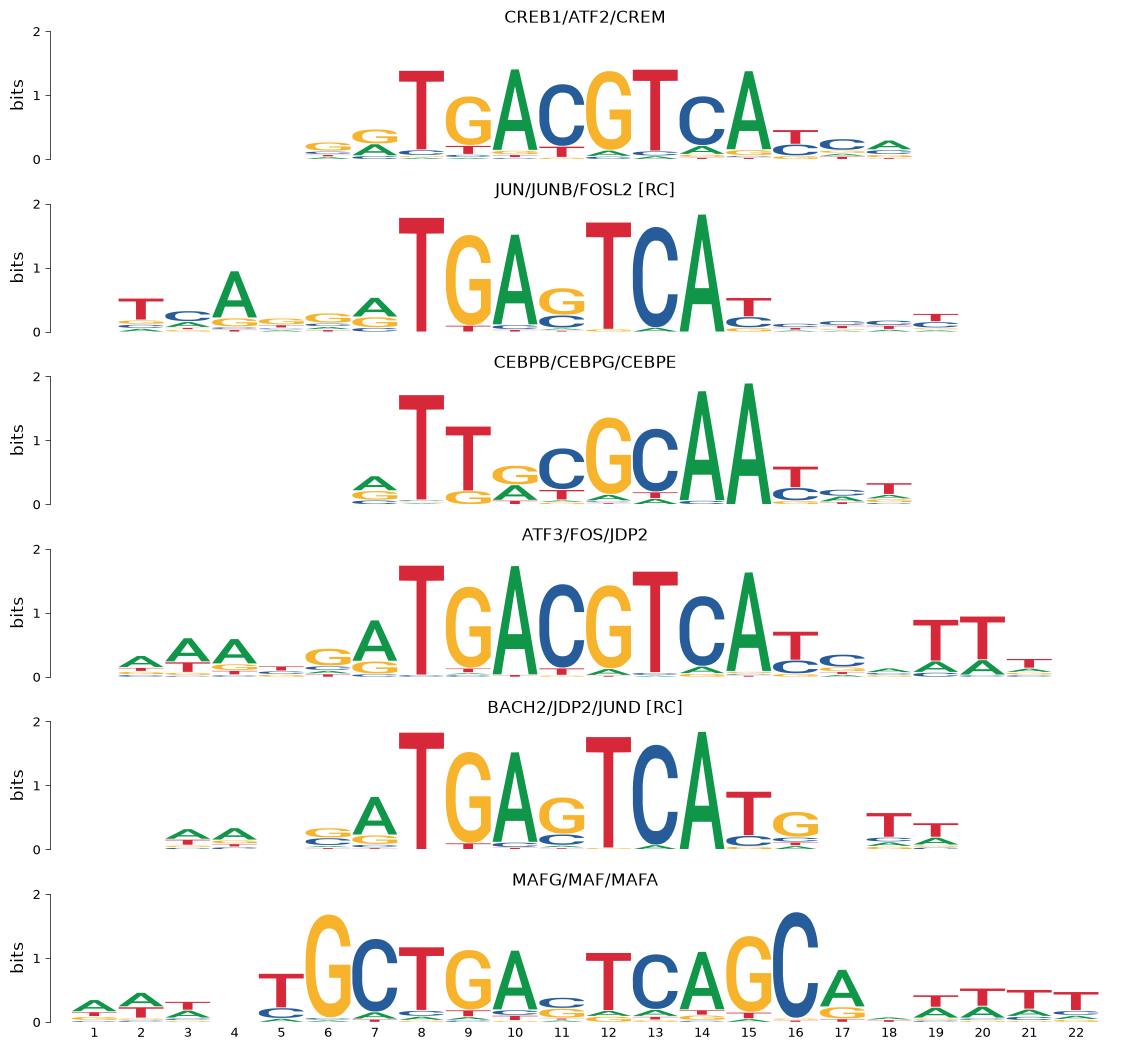

In [13]:
fig = um.view_motifs(library[:6])

To check how much redundancy is left,
[`plot_comparison()`][universalmotif.plot_comparison] draws the similarities
between the library's motifs as a heatmap, ordered by clustering, with their
logos beside the rows:

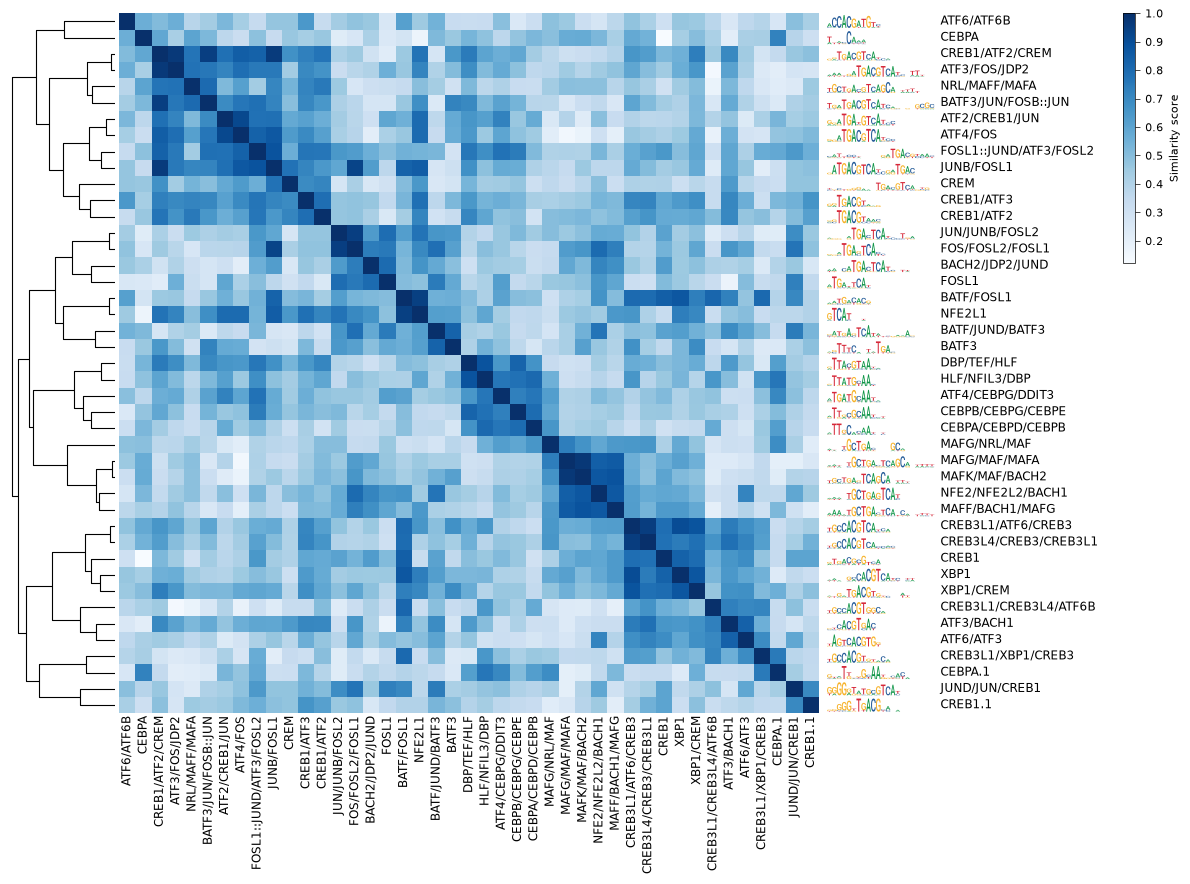

In [14]:
fig = um.plot_comparison(library, nthreads=2)

## Writing the library

Finally, the library can be written to a single file in any of the
supported formats, such as MEME for use with this package or the MEME
suite:

In [15]:
from pathlib import Path
import tempfile

out = Path(tempfile.mkdtemp()) / "bzip_library.meme"
um.write_meme(library, out)
print(len(um.read_meme(out)), "motifs written to", out.name)

43 motifs written to bzip_library.meme


Or, to carry on in Biopython,
[`to_biopython()`][universalmotif.to_biopython] converts the motifs to
`Bio.motifs` objects, here as JASPAR motifs, which Biopython can write in
the JASPAR format. This needs the `biopython` extra.
[`from_biopython()`][universalmotif.from_biopython] goes the other way,
which also covers the motifs returned by pyJASPAR:

In [16]:
from Bio import motifs as bio_motifs

bio = um.to_biopython(library[:2], jaspar=True)
print(bio_motifs.write(bio, "jaspar"))

>CREB1/ATF2/CREM CREB1/ATF2/CREM
A [3543.00 10382.00 533.00 658.00 24052.00 288.00 1826.00 919.00 3761.00 23805.00 874.00 3949.00 13309.00]
C [5270.00 2858.00 1694.00 1305.00 416.00 21839.00 807.00 1438.00 20892.00 522.00 10321.00 14847.00 6772.00]
G [13951.00 12574.00 537.00 20846.00 1267.00 581.00 23745.00 297.00 1245.00 1782.00 2861.00 4094.00 4670.00]
T [3855.00 805.00 23855.00 3810.00 884.00 3911.00 241.00 23965.00 721.00 510.00 12563.00 3729.00 1868.00]
>JUN/JUNB/FOSL2 JUN/JUNB/FOSL2
A [13507.00 10095.00 9834.00 8641.00 16708.00 130.00 199.00 29426.00 925.00 663.00 1906.00 29805.00 633.00 3269.00 7565.00 1117.00 3362.00 19915.00]
C [3202.00 2994.00 4515.00 4453.00 3439.00 290.00 294.00 662.00 18961.00 209.00 28135.00 245.00 9464.00 16367.00 14596.00 4558.00 2854.00 3994.00]
G [10860.00 12043.00 12436.00 12429.00 9831.00 183.00 28984.00 189.00 9155.00 1466.00 268.00 326.00 3575.00 5753.00 4416.00 1245.00 15605.00 3749.00]
T [3063.00 5500.00 3847.00 5109.00 654.00 30029.00 1155.00 

## Where next

The [API reference](../reference/databases.md) describes every option of
the database functions. A library built this way is ready to be scanned
or tested for enrichment, as in the
[ChIP-seq workflow](chipseq-workflow.ipynb) guide.